# Autoencoder vs. PCA on MNIST

**Hayden Willen** | Machine Learning II | University of Virginia School of Data Science

This project builds an autoencoder in PyTorch that compresses 28x28 MNIST digits down to a 2-D bottleneck and reconstructs them. I compare the 2-D representation it learns with a 2-D PCA projection to see which one separates the digits better.

- Based on Michelucci (2022), [An Introduction to Autoencoders](https://arxiv.org/abs/2201.03898)
- Data from [MNIST on OpenML](https://www.openml.org/d/554), loaded with `fetch_openml("mnist_784")`

## 1. Background

These answers are based on *Michelucci (2022)*, [An Introduction to Autoencoders](https://arxiv.org/abs/2201.03898), sections 1, 2.1 to 2.3, and 3.

1. What is the main idea behind an autoencoder?  

The main idea behind an autoencoder is to learn its own compact representation of the data and reconstruct the input from it, so the representation can be used for different applications. The output of an autoencoder is a reconstruction of its own input, rebuilt from the compressed version in the bottleneck.

2. What is the role of the bottleneck layer? 

The bottleneck layer is the middle layer that overlaps the encoder and the decoder and it is the thinnest layer that intentionally has less dimensions than the input layer. The role of the bottleneck layer is to extract the essential features of the input dataset producing a more compressed learned representation as the output.


3. Discuss, in your own words, the applications of autoencoders mentioned in the paper.  

Dimensionality Reduction: 
The use of an autoencoder gives you the advantage of dimensionality reduction and this deals with a very large amount of data efficiently since its training can be done with smaller batches.

Classification: 
Autoencoders doing classification with the latent features can substantially reduce training time without causing a big drop in accuracy.

Anomaly Detection: 
Because the autoencoder learns and reconstructs the input with normal data, it can easily detect huge anomalies and also sees them as a negligible part of the dataset, not allowing them to influence how the autoencoder learns and reconstructs the other observations.

Denoising: 
The autoencoder is developed to auto correct errors. It will reconstruct the input without any added noise, getting stripped down in the bottleneck layer, to give the output cleanly. The model learns to reject the noise because it's random in nature and doesn't connect with the images in any way.


1. What differences would you expect between an autoencoder’s representation and that of PCA if applied as a dimensionality reduction technique?

The main difference between autoencoder and PCA representations is that PCA is linear. It finds linear combinations of the features, while autoencoders allow for flexible, non-linear transformations that can capture more complex structure in the data. Another difference is that autoencoders train on mini batches, so they can handle very large datasets, while standard PCA needs the entire dataset to complete its calculations.

## 2. Data Preparation

The steps below prepare the data.

Each image is scaled to [0,1] using its own min and max, then the data is split 70/15/15 into fitting, tuning, and reporting sets and wrapped in DataLoaders with a batch size of 128.

In [1]:
from sklearn.datasets import fetch_openml
mnist = fetch_openml("mnist_784", version=1, as_frame=False, n_retries=5, delay=2)
X, y = mnist.data, mnist.target.astype(int)

(70000, 784) (70000,)
Raw pixel range: 0 to 255
Normalized range: 0.0 to 1.0
Every image spans [0, 1]: True


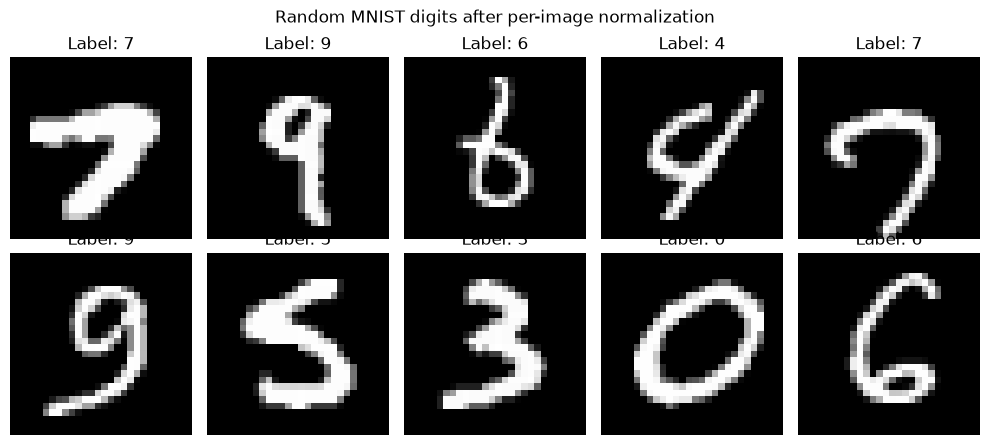

Fitting     49000 samples  (70%)
Tuning      10500 samples  (15%)
Reporting   10500 samples  (15%)
Batch shapes: torch.Size([128, 784]) torch.Size([128])
Batches per loader: 383 83 83


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split


SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print(X.shape, y.shape)
print("Raw pixel range:", X.min(), "to", X.max())


# --- Per-image normalization (fixed transformation: each image uses only its own min/max) ---
X = X.astype(np.float32)

X_min = X.min(axis=1, keepdims=True)
X_max = X.max(axis=1, keepdims=True)
X_norm = (X - X_min) / (X_max - X_min)

print("Normalized range:", X_norm.min(), "to", X_norm.max())
print("Every image spans [0, 1]:",
      np.allclose(X_norm.min(axis=1), 0) and np.allclose(X_norm.max(axis=1), 1))


# --- Visualize random digits ---
rng = np.random.default_rng(SEED)
idx = rng.choice(len(X_norm), size=10, replace=False)

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, i in zip(axes.ravel(), idx):
    ax.imshow(X_norm[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"Label: {y[i]}")
    ax.axis("off")
plt.suptitle("Random MNIST digits after per-image normalization")
plt.tight_layout()
plt.show()


# --- Split: 70% fitting, 15% tuning, 15% reporting (stratified by label) ---
X_fit, X_rest, y_fit, y_rest = train_test_split(
    X_norm, y, test_size=0.30, stratify=y, random_state=SEED
)
X_tune, X_report, y_tune, y_report = train_test_split(
    X_rest, y_rest, test_size=0.50, stratify=y_rest, random_state=SEED
)

for name, arr in [("Fitting", X_fit), ("Tuning", X_tune), ("Reporting", X_report)]:
    print(f"{name:<10} {arr.shape[0]:>6} samples  ({arr.shape[0] / len(X_norm):.0%})")


# --- DataLoaders (only the fitting loader is shuffled) ---
BATCH_SIZE = 128

def make_loader(X_arr, y_arr, shuffle):
    dataset = TensorDataset(torch.tensor(X_arr, dtype=torch.float32),
                            torch.tensor(y_arr, dtype=torch.long))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle)

fitting_loader   = make_loader(X_fit,    y_fit,    shuffle=True)
tuning_loader    = make_loader(X_tune,   y_tune,   shuffle=False)
reporting_loader = make_loader(X_report, y_report, shuffle=False)

X_batch, y_batch = next(iter(fitting_loader))
print("Batch shapes:", X_batch.shape, y_batch.shape)
print("Batches per loader:", len(fitting_loader), len(tuning_loader), len(reporting_loader))


## 3. Autoencoder

This section builds and trains an **autoencoder** to reconstruct the digits.

The model has three layers in both the encoder and decoder.

- **Encoder:** 784 → 128 → 64 → 2. This last layer here is the **bottleneck**.
- **Decoder:** 2 → 64 → 128 → 784  

### 3.1 Model

Each layer follows these rules.

- Each **hidden** layer should include a linear transformation, ReLU activation function, dropout with `p=0.2` and batch normalization steps. I used the order Linear, BatchNorm, ReLU, Dropout. The bottleneck layer is the exception; see next point.
- For the bottleneck, use only a linear transformation, i.e., no activation, batch normalization, or dropout.
- The output layer should have a sigmoid activation function.

In [3]:
import torch.nn as nn

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()
        
        # ENCODING PART: 784 -> 128 -> 64 -> 2
        encoder_list = [
            # 784 -> 128
            nn.Linear(784, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            # 128 -> 64
            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            # 64 -> 2 (bottleneck: linear only)
            nn.Linear(64, 2),
        ]
        self.encoder_list = nn.ModuleList(encoder_list)
        
        # DECODING PART: 2 -> 64 -> 128 -> 784
        decoder_list = [
            # 2 -> 64
            nn.Linear(2, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            # 64 -> 128
            nn.Linear(64, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(p=0.2),
            # 128 -> 784 (output layer: sigmoid to get pixels in [0, 1])
            nn.Linear(128, 784),
            nn.Sigmoid(),
        ]
        self.decoder_list = nn.ModuleList(decoder_list)
        
    def forward(self, X):
        for layer in self.encoder_list:
            X = layer(X)
        for layer in self.decoder_list:
            X = layer(X)
        output = X
        return output


### 3.2 Training

Training uses binary cross-entropy, the Adam optimizer, and early stopping on the tuning set. Two design questions come first.

- Why do you think the output layer of the autoencoder above uses a Sigmoid activation?

The input pixels are normalized to [0,1] before training, and the sigmoid function also outputs values between 0 and 1, so the reconstructed values stay in the same range as the real pixel intensities. Using a linear output layer wouldn't be valid because it could produce negative values or values above 1, which can't be real pixels.

- Based on this, which cost function is most appropriate for this task? Justify your choice.

Binary cross-entropy fits best: since both the sigmoid outputs and target pixels are in [0,1], each pixel can be treated as a probability of being either off/on. BCE also gives stronger gradients than MSE when a prediction is very off, so the model trains faster. 

In [4]:
model = Autoencoder()

criterion = nn.BCELoss()

optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)


In [5]:
class EarlyStopping:
    def __init__(self, patience=10, min_delta=0.0):
        self.patience = patience
        self.min_delta = min_delta
        self.counter = 0
        self.best_loss = None
        self.early_stop = False
        self.best_model_state = None

    def __call__(self, tuning_loss, model):
        if self.best_loss is None or tuning_loss < self.best_loss - self.min_delta:
            self.best_loss = tuning_loss
            self.counter = 0
            self.best_model_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            self.counter += 1
            if self.counter >= self.patience:
                self.early_stop = True

    def restore_best_weights(self, model):
        if self.best_model_state is not None:
            model.load_state_dict(self.best_model_state)


def train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=100, patience=5):
    # Initialize the early stopping object
    early_stopping = EarlyStopping(patience=patience)
    history = {"fitting": [], "tuning": []}

    for epoch in range(n_epochs):
        model.train()
        fitting_cost = 0.0

        for X_batch, _ in fitting_loader:
            outputs = model(X_batch)              # Forward pass
            cost = criterion(outputs, X_batch)    # Target is the input itself
            cost.backward()                       # Compute gradients
            optimizer.step()                      # Update parameters
            optimizer.zero_grad()                 # Reset gradients
            fitting_cost += cost.item() * X_batch.size(0)

        fitting_cost /= len(fitting_loader.dataset)

        # --- Tuning phase ---
        model.eval()
        tuning_cost = 0.0
        with torch.no_grad():
            for X_batch, _ in tuning_loader:
                outputs = model(X_batch)
                cost = criterion(outputs, X_batch)
                tuning_cost += cost.item() * X_batch.size(0)

        tuning_cost /= len(tuning_loader.dataset)

        # --- Save metrics ---
        history["fitting"].append(fitting_cost)
        history["tuning"].append(tuning_cost)

        print(f"Epoch [{epoch+1}/{n_epochs}]  Fitting Cost: {fitting_cost:.5f}  Tuning Cost: {tuning_cost:.5f}")

        # --- Early stopping check ---
        early_stopping(tuning_cost, model)
        if early_stopping.early_stop:
            print(f"Stopping early at epoch {epoch+1}")
            early_stopping.restore_best_weights(model)
            return model, history

    return model, history


Train the model. Early stopping ends training once the tuning loss stops improving for 5 epochs.

In [6]:
model, history = train_autoencoder(model, fitting_loader, tuning_loader, n_epochs=50, patience=5)

Epoch [1/50]  Fitting Cost: 0.25864  Tuning Cost: 0.21130
Epoch [2/50]  Fitting Cost: 0.21340  Tuning Cost: 0.20425
Epoch [3/50]  Fitting Cost: 0.20925  Tuning Cost: 0.20058
Epoch [4/50]  Fitting Cost: 0.20710  Tuning Cost: 0.19859
Epoch [5/50]  Fitting Cost: 0.20575  Tuning Cost: 0.19732
Epoch [6/50]  Fitting Cost: 0.20489  Tuning Cost: 0.19671
Epoch [7/50]  Fitting Cost: 0.20422  Tuning Cost: 0.19606
Epoch [8/50]  Fitting Cost: 0.20369  Tuning Cost: 0.19514
Epoch [9/50]  Fitting Cost: 0.20334  Tuning Cost: 0.19511
Epoch [10/50]  Fitting Cost: 0.20266  Tuning Cost: 0.19398
Epoch [11/50]  Fitting Cost: 0.20250  Tuning Cost: 0.19376
Epoch [12/50]  Fitting Cost: 0.20223  Tuning Cost: 0.19360
Epoch [13/50]  Fitting Cost: 0.20204  Tuning Cost: 0.19312
Epoch [14/50]  Fitting Cost: 0.20168  Tuning Cost: 0.19299
Epoch [15/50]  Fitting Cost: 0.20153  Tuning Cost: 0.19271
Epoch [16/50]  Fitting Cost: 0.20122  Tuning Cost: 0.19214
Epoch [17/50]  Fitting Cost: 0.20116  Tuning Cost: 0.19259
Epoch 

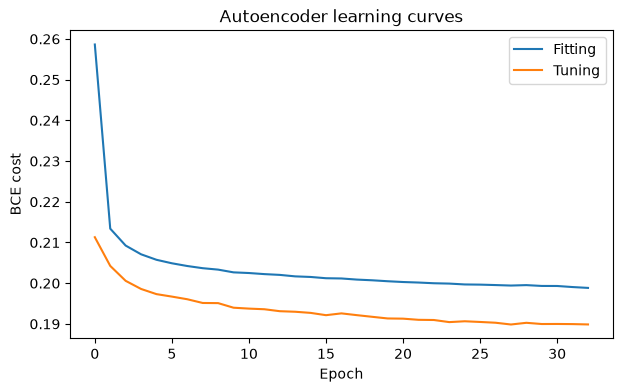

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(history["fitting"], label="Fitting")
plt.plot(history["tuning"], label="Tuning")
plt.xlabel("Epoch")
plt.ylabel("BCE cost")
plt.title("Autoencoder learning curves")
plt.legend()
plt.show()


### 3.3 Reconstruction

Reconstructions of the first 10 digits in the reporting set, compared with the originals. 

Was the reconstruction good? 

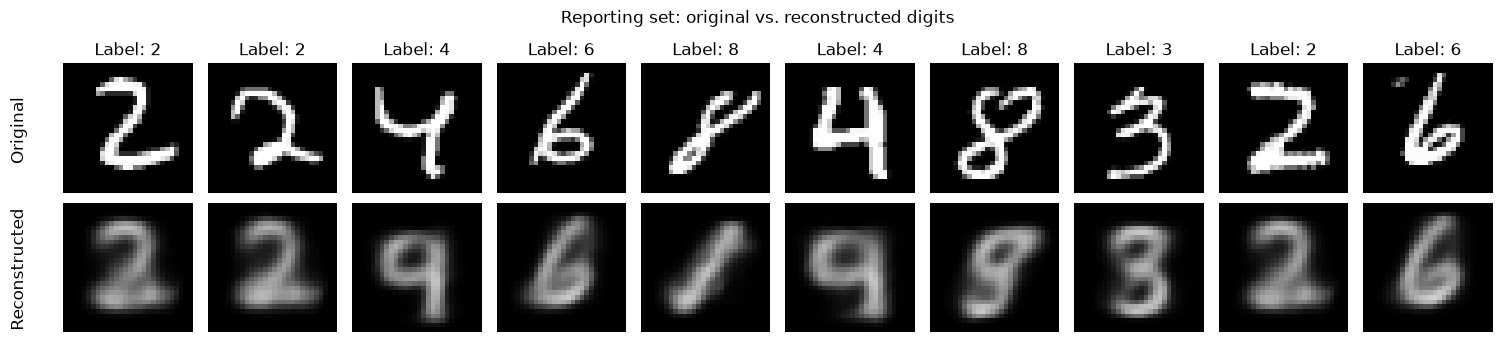

In [8]:
model.eval()
X_report_batch, y_report_batch = next(iter(reporting_loader))

with torch.no_grad():
    reconstructed = model(X_report_batch)

n = 10
fig, axes = plt.subplots(2, n, figsize=(15, 3.5))
for i in range(n):
    axes[0, i].imshow(X_report_batch[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    axes[0, i].set_title(f"Label: {y_report_batch[i].item()}")
    axes[0, i].axis("off")

    axes[1, i].imshow(reconstructed[i].reshape(28, 28), cmap="gray", vmin=0, vmax=1)
    axes[1, i].axis("off")

axes[0, 0].text(-12, 14, "Original", fontsize=12, rotation=90, va="center")
axes[1, 0].text(-12, 14, "Reconstructed", fontsize=12, rotation=90, va="center")
plt.suptitle("Reporting set: original vs. reconstructed digits")
plt.tight_layout()
plt.show()


In [9]:
reporting_cost = 0.0
with torch.no_grad():
    for X_batch, _ in reporting_loader:
        outputs = model(X_batch)
        reporting_cost += criterion(outputs, X_batch).item() * X_batch.size(0)
reporting_cost /= len(reporting_loader.dataset)

print(f"Reporting BCE cost: {reporting_cost:.5f}")


Reporting BCE cost: 0.18973


The reconstruction was solid. It often confused numbers that were similar such as 4 and 9, and 3 and 8. It also mixed up 8 and 9 once. The reconstruction error was still fairly large.

## 4. Learned 2-D Representation

This section looks at the latent representations learned by the autoencoder.

1. `extract_latent_features` passes the reporting set through the encoder only, giving each image a 2-D point.
2. Plot the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.


In [10]:
def extract_latent_features(model, dataloader): 
    model.eval()
    latents = []
    labels = []

    with torch.no_grad():
        for X_batch, y_batch in dataloader:
            
            # Apply only the encoder layers to get the 2D bottleneck features
            encoded = X_batch
            for layer in model.encoder_list:
                encoded = layer(encoded)
            latents.append(encoded.numpy())
            labels.append(y_batch.numpy())

    # Concatenate all batches
    latents = np.concatenate(latents, axis=0)
    labels = np.concatenate(labels, axis=0)
    return latents, labels


Extract the 2-D features for the reporting set.

In [13]:
latents_autoencoder, labels = extract_latent_features(model, reporting_loader)
print(latents_autoencoder.shape, labels.shape)

(10500, 2) (10500,)


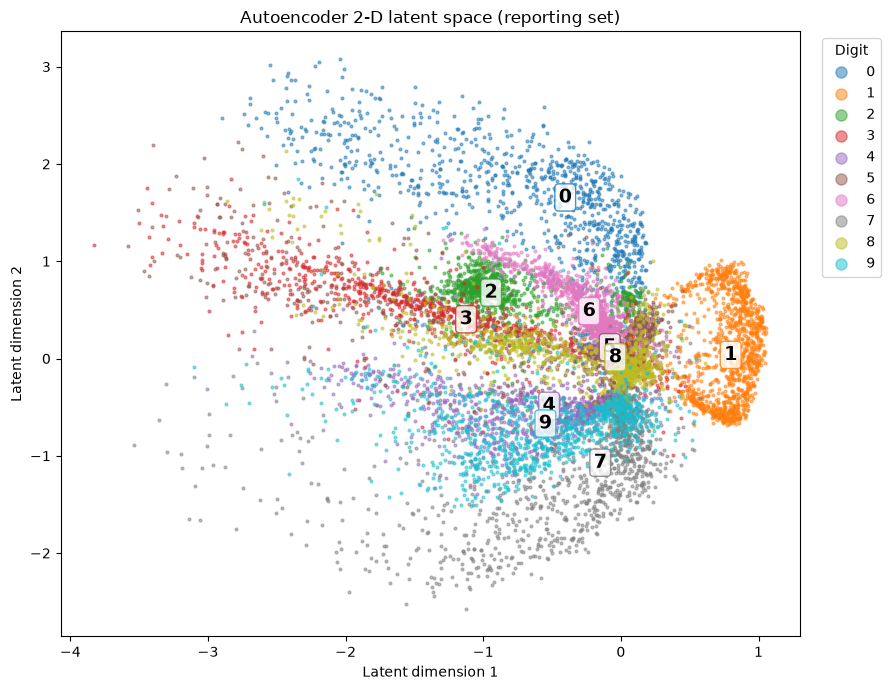

In [14]:
fig, ax = plt.subplots(figsize=(9, 7))

cmap = plt.get_cmap("tab10")
for digit in range(10):
    mask = labels == digit
    ax.scatter(latents_autoencoder[mask, 0], latents_autoencoder[mask, 1],
               s=4, alpha=0.5, color=cmap(digit), label=str(digit))

    # Put the digit at the median of its cluster
    cx, cy = np.median(latents_autoencoder[mask], axis=0)
    ax.text(cx, cy, str(digit), fontsize=14, fontweight="bold",
            ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=cmap(digit), alpha=0.8))

ax.set_xlabel("Latent dimension 1")
ax.set_ylabel("Latent dimension 2")
ax.set_title("Autoencoder 2-D latent space (reporting set)")
ax.legend(title="Digit", markerscale=4, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


## 5. Comparison with PCA

This section compares the autoencoder's representation with a 2-D PCA.

1. Fit a 2-component PCA on the fitting and tuning sets, then apply it to the reporting set.
2. Visualize the reduced 2D data as a scatterplot, coloring each point by its corresponding digit label.
3. Compare the structure of the two plots (Autoencoder vs. PCA).

In [15]:
from sklearn.decomposition import PCA

# Learn the 2 principal components from everything except the reporting set
X_pca_fit = np.concatenate([X_fit, X_tune], axis=0)

pca = PCA(n_components=2, random_state=SEED)
pca.fit(X_pca_fit)

# Only transform the reporting set
latents_pca = pca.transform(X_report)
labels_pca = y_report

print(latents_pca.shape, labels_pca.shape)
print("Explained variance ratio:", pca.explained_variance_ratio_)
print(f"Total variance explained by 2 components: {pca.explained_variance_ratio_.sum():.2%}")


(10500, 2) (10500,)
Explained variance ratio: [0.09745678 0.0714606 ]
Total variance explained by 2 components: 16.89%


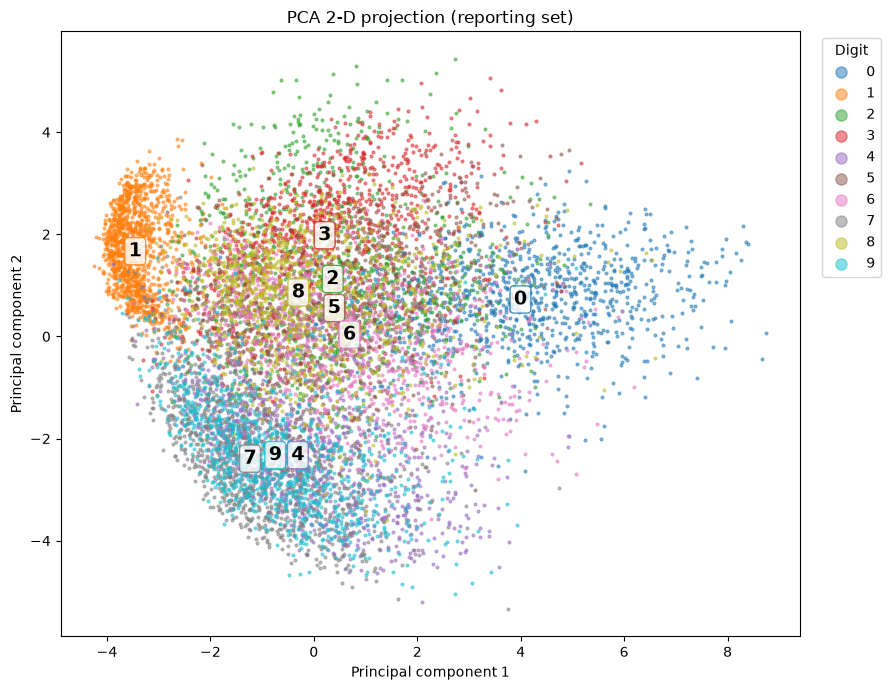

In [16]:
fig, ax = plt.subplots(figsize=(9, 7))

cmap = plt.get_cmap("tab10")
for digit in range(10):
    mask = labels_pca == digit
    ax.scatter(latents_pca[mask, 0], latents_pca[mask, 1],
               s=4, alpha=0.5, color=cmap(digit), label=str(digit))

    # Put the digit at the median of its cluster
    cx, cy = np.median(latents_pca[mask], axis=0)
    ax.text(cx, cy, str(digit), fontsize=14, fontweight="bold",
            ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=cmap(digit), alpha=0.8))

ax.set_xlabel("Principal component 1")
ax.set_ylabel("Principal component 2")
ax.set_title("PCA 2-D projection (reporting set)")
ax.legend(title="Digit", markerscale=4, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()


The autoencoder 2-D projection is clearly superior to the PCA 2-D projection. In the PCA projection, the only number that is clearly identified consistently is 1. Whereas in the autoencoder 2-D projection, most numbers are in their own general area with only one or two common misidentified patterns.

## What I found

- The autoencoder trained for 33 epochs before early stopping, which kept the best weights from epoch 28. Its reporting set BCE was 0.18973, close to the tuning loss of 0.18986, so it did not overfit.
- Reconstructions keep the general shape of each digit but come out blurry, since every image has to pass through only 2 numbers.
- Similar digits like 4 and 9, and 3 and 8, sometimes reconstruct as each other. Digits like 2 and 6 reconstruct consistently.
- In 2-D, the autoencoder separates most digits into their own regions. The 2 PCA components explain only 16.89% of the variance, and only the digit 1 forms a clear group.
- A non-linear 2-D bottleneck keeps much more of the digit structure than a linear 2-D projection.